Problem 1
(a)


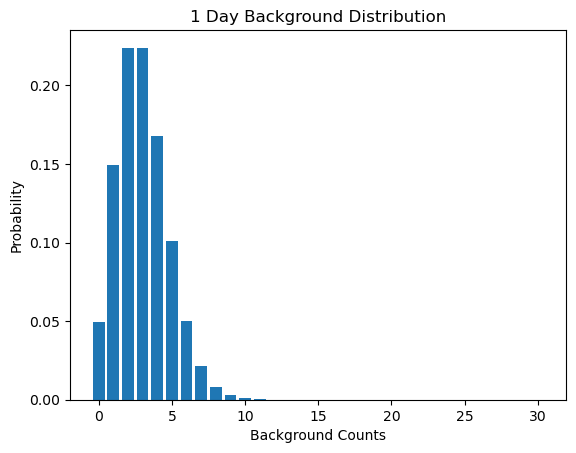


(b)



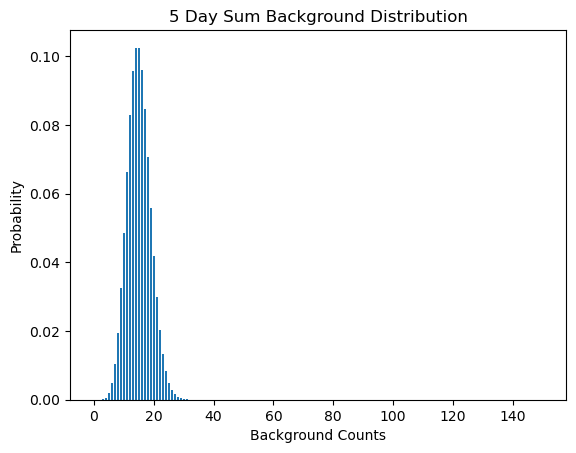


(c)



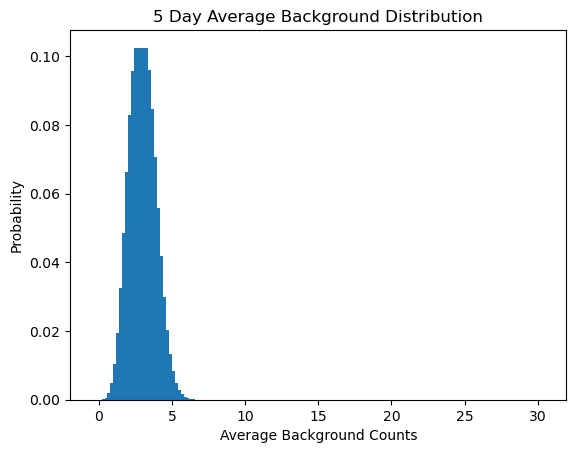

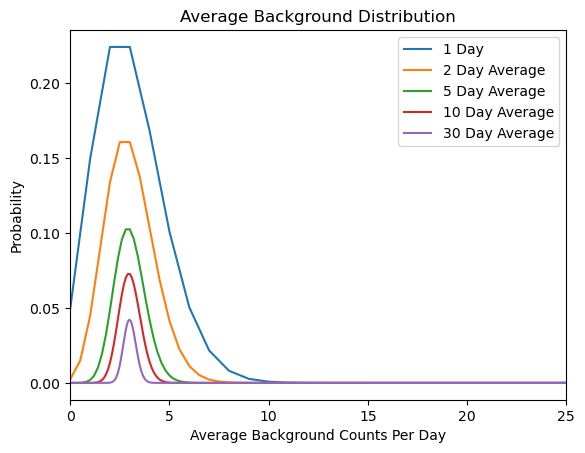


(d)

For 10 days, the expected background counts is 30 and the observed count is 60. 
The probability of the Poisson distribution fluctuating to over 60 counts of gamma rays is 4.7691146041466705 sigma.


In [23]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#Problem 1
#(a) 

print("Problem 1\n(a)")
X = 3      # average background counts per day
Y = 6      # hypothetical source counts per day

counts = np.arange(0, 31) # creates an array [0,1, ... , 30] that indicates how many gamma rays could be counted per day.
background = stats.poisson.pmf(counts, mu=X)
plt.bar(counts, background)

plt.xlabel("Background Counts")
plt.ylabel("Probability")
plt.title("1 Day Background Distribution")

plt.show()

#(b)
print("\n(b)\n")

two_days = np.convolve(background, background, mode='full')
four_days = np.convolve(two_days, two_days, mode='full')
five_days = np.convolve(four_days, background, mode='full')
plt.bar(np.arange(len(five_days)), five_days)

plt.xlabel("Background Counts")
plt.ylabel("Probability")
plt.title("5 Day Sum Background Distribution")

plt.show()

print("\n(c)\n")

plt.bar(np.arange(len(five_days))/5, five_days)
plt.xlabel("Average Background Counts")
plt.ylabel("Probability")
plt.title("5 Day Average Background Distribution")

plt.show()

ten_days = np.convolve(five_days, five_days, mode='full')
twenty_days = np.convolve(ten_days, ten_days, mode='full')
thirty_days = np.convolve(twenty_days, ten_days, mode='full')
plt.plot(counts, background, label = '1 Day')
plt.plot(np.arange(len(two_days))/2, two_days, label="2 Day Average")
plt.plot(np.arange(len(five_days))/5, five_days, label="5 Day Average")
plt.plot(np.arange(len(ten_days))/10, ten_days, label="10 Day Average")
plt.plot(np.arange(len(thirty_days))/30, thirty_days, label="30 Day Average")

plt.xlabel("Average Background Counts Per Day")
plt.ylabel("Probability")
plt.title("Average Background Distribution")

plt.legend()
plt.xlim(0,25)
plt.show()

print("\n(d)\n")

N = 10 # Random number (N)
observed = Y * N
background_mean = X * N

p_value = stats.poisson.sf(observed - 1, mu=background_mean)
sigma = stats.norm.isf(p_value)
print(f"""For {N} days, the expected background counts is {background_mean} and the observed count is {observed}. 
The probability of the Poisson distribution fluctuating to over {observed} counts of gamma rays is {sigma} sigma.""")



Problem 2
(a)


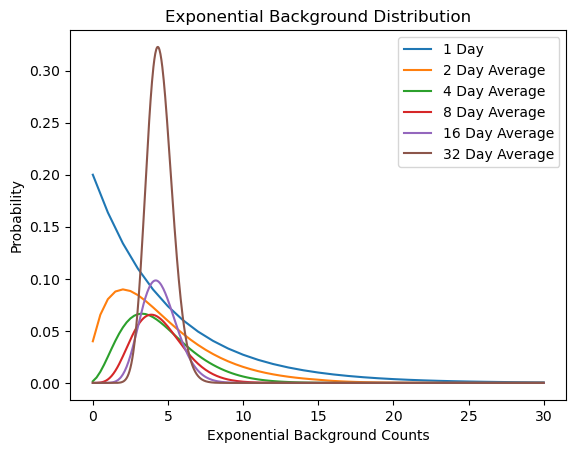


(d)

The exponential distribution looks like a Gaussian distribution after approximately 32 convolutions.


In [30]:
#Problem 2
#(a) 

print("Problem 2\n(a)")
counts_2 = np.arange(0, 31) # creates an array [0,1, ... , 30] that indicates how many gamma rays could be counted per day.
expon_val = stats.expon.pdf(counts_2, scale=5)
e_twodays = np.convolve(expon_val, expon_val, mode='full')
e_fourdays = np.convolve(e_twodays, e_twodays, mode='full')
e_eightdays = np.convolve(e_fourdays, e_fourdays, mode='full')
e_sixteendays = np.convolve(e_eightdays, e_eightdays, mode='full')
e_thirtytwodays = np.convolve(e_sixteendays, e_sixteendays, mode='full')

plt.plot(counts_2, expon_val, label="1 Day")
plt.plot(np.arange(len(e_twodays))/2, e_twodays, label="2 Day Average")
plt.plot(np.arange(len(e_fourdays))/4, e_fourdays, label="4 Day Average")
plt.plot(np.arange(len(e_eightdays))/8, e_eightdays, label="8 Day Average")
plt.plot(np.arange(len(e_sixteendays))/16, e_sixteendays, label="16 Day Average")
plt.plot(np.arange(len(e_thirtytwodays))/32, e_thirtytwodays, label="32 Day Average")

plt.xlabel("Exponential Background Counts")
plt.ylabel("Probability")
plt.title("Exponential Background Distribution")
plt.legend()

plt.show()

#(b)
print("\n(b)\n")
print("The exponential distribution looks like a Gaussian distribution after approximately 32 convolutions. This is indicated by a more central mean than the other average distributions.")

Problem 3
(a)
Background width: 2.0
Signal strength: 8.0
Significance: 4.0 sigma

(b)



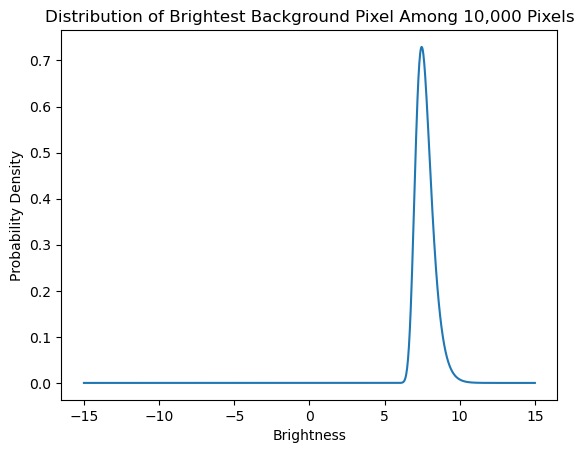


(c)

One-pixel probability: 3.167124183311986e-05
Probability of at least one such pixel: 0.27146341412315356
Adjusted significance: 0.6083930373625848 sigma


In [33]:
#Problem 3
#(a) 

print("Problem 3\n(a)")

X = 2.0   # width (standard deviation) of background Gaussian
Y = 8.0   # measured signal

sigma = Y / X

print("Background width:", X)
print("Signal strength:", Y)
print("Significance:", sigma, "sigma")

#(b)
print("\n(b)\n")

X = 2.0                # Gaussian background width
N_pixels = 10000       # number of pixels searched

x = np.linspace(-15, 15, 1000)
#Creates an array of possible brightness values from (-15, 15)

single_pixel_cdf = stats.norm.cdf(x, loc=0, scale=X)

max_pixel_cdf = single_pixel_cdf ** N_pixels
#This line of code tells us the probability that all pixels have a brightness of less than 2.0
#which equates to the probability that the BRIGHTEST pixel is less than 2.0

#Now let's try graphing the pdf of this 10000 pixel problem
single_pixel_pdf = stats.norm.pdf(x, loc=0, scale=X)

max_pixel_pdf = (N_pixels * single_pixel_pdf * single_pixel_cdf ** (N_pixels - 1))
#single_pixel_pdf = probability that a single pixel landed on the desired brightness
#multiply by N_pixels because it could have been any 10000 of the pixels
#multiply by the cdf to the power of N_pixels - 1 for the other 9999 pixels that did not achieve that brightness.

plt.plot(x, max_pixel_pdf)

plt.xlabel("Brightness")
plt.ylabel("Probability Density")
plt.title("Distribution of Brightest Background Pixel Among 10,000 Pixels")

plt.show()

#(c)
print("\n(c)\n")
p_single = stats.norm.sf(Y, loc=0, scale=X)
# probability of getting a background fluctuation of at least 8
p_any = 1 - (1 - p_single)**N_pixels
# probability that at least one of those pixels reaches a value of 8
sigma = stats.norm.isf(p_any) # back in sigma form

print("One-pixel probability:", p_single)
print("Probability of at least one such pixel:", p_any)
print("Adjusted significance:", sigma, "sigma")

In [38]:
#Problem 4
#(a) 

print("Problem 4\n(a)")

X = 2.0

signal_5sigma = 5 * X

print("Signal required for 5-sigma:", signal_5sigma)

#(b)
print("\n(b)\n")
N_pixels = 10000

p_5sigma = stats.norm.sf(5)

p_single = 1 - (1 - p_5sigma)**(1 / N_pixels)
#You take the equation for p_any from problem 3(c) and solve for p_single after replacing p_any with p_5sigma. 

z_required = stats.norm.isf(p_single) # find the sigma associated with that probability
signal_required = z_required * X # This is the signal required to get that sigma

print("5-sigma global probability:", p_5sigma)
print("Required one-pixel probability:", p_single)
print("Required local significance:", z_required, "sigma")
print("Signal required:", signal_required)

#(c)
print("\n(c)\n")

sensitivity = signal_required/signal_5sigma*100 - 100
print(f"It must be approximately {sensitivity}% more sensitive.")
print("""Because the tails of Gaussian distributions fall at such a fast rate, the sensitivity penalty of a high trials factor remains low.
Hence, to find an incredibly rare occurrence, one does not need to go from 5 sigma to 50 sigma. Just going to 6.5 sigma would do, which equates to a measly 31% increase for 10000 pixels.""")


#(d)
print("\n(d)\n")

trials = [1, 10, 100, 1000, 10000, 100000, 1000000]

for N_pixels in trials:

    p_single_d = 1 - (1 - p_5sigma)**(1 / N_pixels)

    z_required_d = stats.norm.isf(p_single_d)

    signal_required_d = z_required_d * X

    print("Trials:", N_pixels,"-->Required sigma:", z_required_d,"-->Required signal:", signal_required_d)


Problem 4
(a)
Signal required for 5-sigma: 10.0

(b)

5-sigma global probability: 2.866515718791933e-07
Required one-pixel probability: 2.8665181339704304e-11
Required local significance: 6.550537486891655 sigma
Signal required: 13.10107497378331

(c)

It must be approximately 31.010749737833123% more sensitive.
Because the tails of Gaussian distributions fall at such a fast rate, the sensitivity penalty of a high trials factor remains low.
Hence, to find an incredibly rare occurrence, one does not need to go from 5 sigma to 50 sigma. Just going to 6.5 sigma would do, which equates to a measly 31% increase for 10000 pixels.

(d)

Trials: 1 -->Required sigma: 4.999999999970176 -->Required signal: 9.999999999940352
Trials: 10 -->Required sigma: 5.426933979854786 -->Required signal: 10.853867959709572
Trials: 100 -->Required sigma: 5.824364520224008 -->Required signal: 11.648729040448016
Trials: 1000 -->Required sigma: 6.197600812240388 -->Required signal: 12.395201624480777
Trials: 10000